# Importing all necessary libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

In [18]:
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef
)

# Load UCI Adult dataset

In [2]:
col_names = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

In [3]:
url_train = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
url_test = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

In [5]:
df_1 = pd.read_csv(url_train, names=col_names, na_values="?", skipinitialspace=True)
df_2 = pd.read_csv(url_test, names=col_names, na_values="?", skipinitialspace=True, skiprows=1)

In [10]:
raw_df = pd.concat([df_1, df_2], ignore_index=True)
raw_df["income"] = raw_df["income"].str.replace(".", "", regex=False).str.strip()

print("Dataset Shape:", raw_df.shape)
print("\nMissing Values:\n", raw_df.isnull().sum()[raw_df.isnull().sum() > 0])
print("\nClass Balance (%):\n", (raw_df["income"].value_counts(normalize=True) * 100).round(2))

Dataset Shape: (48842, 15)

Missing Values:
 workclass         2799
occupation        2809
native-country     857
dtype: int64

Class Balance (%):
 income
<=50K    76.07
>50K     23.93
Name: proportion, dtype: float64


# Preprocessing & Saving test_data.csv

In [11]:
# Remove duplicates
clean_df = raw_df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", clean_df.shape[0])

X = clean_df.drop(columns=["income"])
y = (clean_df["income"] == ">50K").astype(int)

Rows after removing duplicates: 48790


In [12]:
# Stratified 80:20 split with fixed seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

In [13]:
# Save test_data.csv in root folder as required
test_out = X_test.copy()
test_out["income"] = y_test
test_out.to_csv("../test_data.csv", index=False)

In [15]:
# Define numeric and categorical pipelines
num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = X.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), cat_features)
])

In [16]:
# Fit strictly on training data
X_train_proc = preprocessor.fit_transform(X_train)

# Train All 5 Models & Evaluate on test_data.csv

In [19]:
# Load test_data.csv explicitly for evaluation
test_loaded = pd.read_csv("../test_data.csv")
X_test_eval = test_loaded.drop(columns=["income"])
y_test_eval = test_loaded["income"]
X_test_proc = preprocessor.transform(X_test_eval)

# Define the 5 classification models (customize hyperparameters as needed)
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "kNN": KNeighborsClassifier(n_neighbors=11),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=150, max_depth=15, random_state=42)
}

metrics_list = []

for model_name, clf in classifiers.items():
    clf.fit(X_train_proc, y_train)
    y_pred = clf.predict(X_test_proc)
    y_prob = clf.predict_proba(X_test_proc)[:, 1]

    metrics_list.append({
        "ML Model Name": model_name,
        "Accuracy": round(accuracy_score(y_test_eval, y_pred), 4),
        "AUC": round(roc_auc_score(y_test_eval, y_prob), 4),
        "Precision": round(precision_score(y_test_eval, y_pred), 4),
        "Recall": round(recall_score(y_test_eval, y_pred), 4),
        "F1": round(f1_score(y_test_eval, y_pred), 4),
        "MCC": round(matthews_corrcoef(y_test_eval, y_pred), 4)
    })

results_df = pd.DataFrame(metrics_list)
display(results_df)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8520,0.9081,0.7304,0.6053,0.6620,0.5724
1,Decision Tree,0.8647,0.9048,0.7746,0.6134,0.6847,0.6066
2,kNN,0.8473,0.8908,0.7057,0.6211,0.6607,0.5647
3,Naive Bayes,0.5990,0.8174,0.3672,0.9336,0.5271,0.3736
4,Random Forest (Ensemble),0.8676,0.9201,0.7983,0.5980,0.6838,0.6123


# Visualization of All 6 Metrics

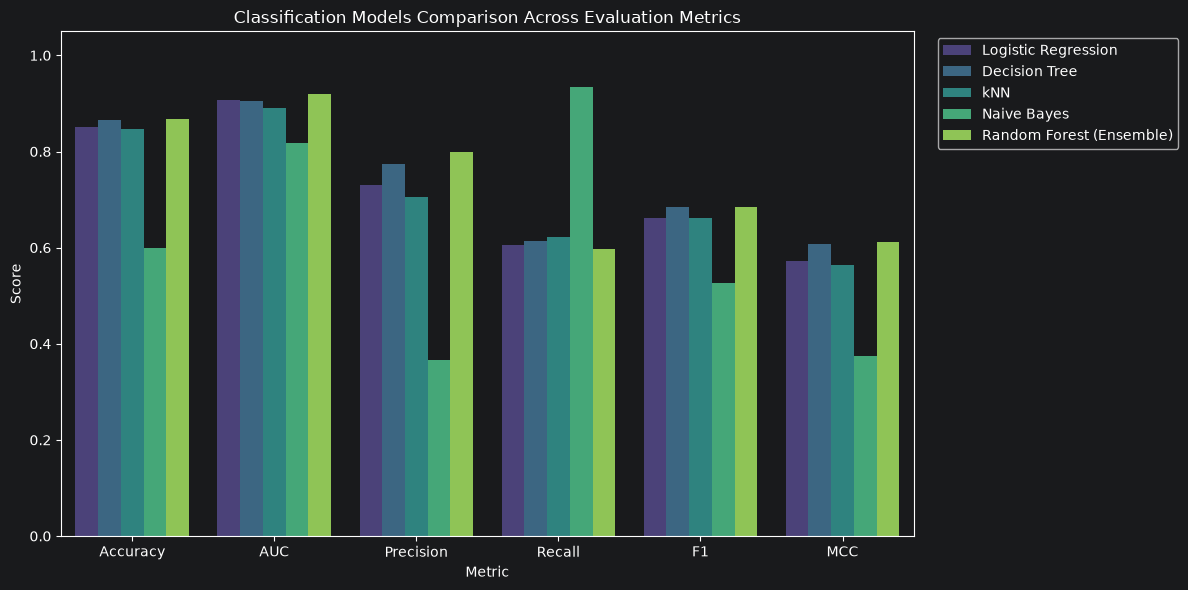

In [20]:
melted_df = results_df.melt(id_vars="ML Model Name", var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 6))
sns.barplot(data=melted_df, x="Metric", y="Score", hue="ML Model Name", palette="viridis")
plt.title("Classification Models Comparison Across Evaluation Metrics")
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../metrics_comparison.png", dpi=300)
plt.show()